## F1 Tire Degradation and Performance Decay Analysis
### Bahrain Grand Prix 2023 — Tire Degradation & Undercut Optimization

**Authors:** B Sudharshan, Arush Srivastava, Dharanitharan D
**Context:** Predictive Analytics Project

**Objective:** Model non-linear tire degradation, build predictive models, and run Monte Carlo simulations to find the optimal pit strategy.

**Key Techniques:**
- Physics-based fuel burn correction
- Predicting Pace Drop-off (Lap Time Delta) to isolate tire wear from baseline car pace
- Polynomial & XGBoost regression (with Monotonic Constraints)
- Monte Carlo race simulation (10,000 runs)

In [1]:
# !pip install -q fastf1 dtaidistance optuna shap umap-learn statsmodels tabulate  # disabled for offline execution (packages already installed)

In [1]:
import fastf1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import xgboost as xgb
import optuna
import shap
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, learning_curve, GroupShuffleSplit
from sklearn.manifold import TSNE
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from dtaidistance import dtw
from statsmodels.nonparametric.smoothers_lowess import lowess
import logging
import warnings
import os
import time
from tqdm import tqdm
from IPython.display import display, HTML, Markdown
from tabulate import tabulate

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Logging configuration
logging.basicConfig(level=logging.INFO, format='%(asctime)s | %(levelname)s | %(message)s')
logger = logging.getLogger('PitWall')
logger.setLevel(logging.INFO)

### Global Configurations & Constants

In [2]:
cache_dir = 'cache'
os.makedirs(cache_dir, exist_ok=True)
fastf1.Cache.enable_cache(cache_dir)

COMPOUND_COLORS = {
    'SOFT': '#FF3333',
    'MEDIUM': '#FFF200',
    'HARD': '#000000',
}

FUEL_EFFECT_K       = 0.055
RACE_LAPS           = 57
FUEL_LOAD_START_KG  = 110
FUEL_PER_LAP        = FUEL_LOAD_START_KG / RACE_LAPS
DELTA_PER_LAP       = FUEL_EFFECT_K * FUEL_PER_LAP

### Data Loading: Session Telemetry & Laps

In [3]:
session = fastf1.get_session(2023, 'Bahrain', 'R')
session.load(telemetry=True, weather=True, messages=True)

logger.info(f"Session loaded: {session.event['EventName']} {session.event.year}")

laps_raw = session.laps.copy()

lap_columns = [
    'Driver', 'LapNumber', 'LapTime', 'Compound', 'TyreLife',
    'Stint', 'PitInTime', 'PitOutTime', 'TrackStatus', 'IsAccurate',
    'Team', 'Position', 'Time', 'LapStartTime'
]

available_cols = [c for c in lap_columns if c in laps_raw.columns]
laps_df = laps_raw[available_cols].copy()

# Convert timedelta to seconds for numerical modeling
laps_df['LapTimeSeconds'] = laps_df['LapTime'].dt.total_seconds()
laps_df = laps_df.dropna(subset=['LapTimeSeconds'])

laps_df.head()

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.9.0]
2026-10-26 12:06:56,303 | INFO | Loading data for Bahrain Grand Prix - Race [v3.9.0]
req            INFO 	Using cached data for session_info
2026-10-26 12:06:56,303 | INFO | Using cached data for session_info
req            INFO 	Using cached data for driver_info
2026-10-26 12:06:56,312 | INFO | Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
2026-10-26 12:06:56,403 | INFO | Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
2026-10-26 12:06:56,404 | INFO | Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
2026-10-26 12:06:56,412 | INFO | Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
2026-10-26 12:06:56,429 | INFO | Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
2026-

,Driver,LapNumber,LapTime,Compound,TyreLife,Stint,PitInTime,PitOutTime,TrackStatus,IsAccurate,Team,Position,Time,LapStartTime,LapTimeSeconds
0,VER,1.0,0 days 00:01:39.019000,SOFT,4.0,1.0,NaT,NaT,12,False,Red Bull Racing,1.0,0 days 01:04:15.902000,0 days 01:02:36.652000,99.019
1,VER,2.0,0 days 00:01:37.974000,SOFT,5.0,1.0,NaT,NaT,12,True,Red Bull Racing,1.0,0 days 01:05:53.876000,0 days 01:04:15.902000,97.974
2,VER,3.0,0 days 00:01:38.006000,SOFT,6.0,1.0,NaT,NaT,1,True,Red Bull Racing,1.0,0 days 01:07:31.882000,0 days 01:05:53.876000,98.006
3,VER,4.0,0 days 00:01:37.976000,SOFT,7.0,1.0,NaT,NaT,1,True,Red Bull Racing,1.0,0 days 01:09:09.858000,0 days 01:07:31.882000,97.976
4,VER,5.0,0 days 00:01:38.035000,SOFT,8.0,1.0,NaT,NaT,1,True,Red Bull Racing,1.0,0 days 01:10:47.893000,0 days 01:09:09.858000,98.035


### Data Processing: Track Position & Air Context
Computing track position proxies to distinguish between clean air and dirty air (traffic).

In [4]:
laps_df = laps_df.sort_values(['Driver', 'LapNumber'])
laps_df['CumulativeRaceTime'] = laps_df.groupby('Driver')['LapTimeSeconds'].cumsum()

gap_records = []
for lap_num, group in laps_df.groupby('LapNumber'):
    sorted_grp = group.sort_values('CumulativeRaceTime').reset_index()
    for i in range(len(sorted_grp)):
        idx = sorted_grp.loc[i, 'index']
        if i == 0:
            gap = np.nan  # Race leader
        else:
            gap = sorted_grp.loc[i, 'CumulativeRaceTime'] - sorted_grp.loc[i - 1, 'CumulativeRaceTime']
        gap_records.append({'_idx': idx, 'GapToAhead': gap})

gap_df = pd.DataFrame(gap_records).set_index('_idx')
laps_df = laps_df.join(gap_df)

# Flag laps with >2s gap to the car ahead as 'Clean Air'
laps_df['CleanAir'] = (laps_df['GapToAhead'] > 2.0) | (laps_df['GapToAhead'].isna())

# Merge track and weather data using a nearest-time rolling join
weather_df = session.weather_data[['Time', 'AirTemp', 'TrackTemp', 'Humidity']].copy()

merge_key = 'LapStartTime' if 'LapStartTime' in laps_df.columns else 'Time'

laps_sorted = laps_df.sort_values(merge_key).copy()
weather_sorted = weather_df.sort_values('Time').copy()

laps_df = pd.merge_asof(
    laps_sorted,
    weather_sorted,
    left_on=merge_key,
    right_on='Time',
    direction='nearest',
    suffixes=('', '_weather')
)

if 'Time_weather' in laps_df.columns:
    laps_df = laps_df.drop(columns=['Time_weather'])

# Detect Safety Car / Virtual Safety Car deployments
if 'TrackStatus' in laps_df.columns:
    laps_df['IsUnderSC'] = laps_df['TrackStatus'].astype(str).str.contains('[4567]', regex=True, na=False)
else:
    laps_df['IsUnderSC'] = False

### Data Preprocessing Pipeline
Filtering out unrepresentative laps to isolate genuine tire degradation trends.

In [5]:
laps_df = laps_df[laps_df['IsAccurate'] == True].copy()

sc_laps_for_viz = laps_df[laps_df['IsUnderSC'] == True].copy()
laps_df = laps_df[laps_df['IsUnderSC'] == False].copy()

pit_mask = laps_df['PitInTime'].notna() | laps_df['PitOutTime'].notna()
laps_df = laps_df[~pit_mask].copy()

dirty_air_laps_for_viz = laps_df[laps_df['CleanAir'] == False].copy()
clean_air_laps_for_viz = laps_df[laps_df['CleanAir'] == True].copy()
laps_df = laps_df[laps_df['CleanAir'] == True].copy()

def remove_outliers(group):
    """
    Removes statistical anomalies from a driver's stint to prevent 
    driver errors (e.g., lock-ups, track limit variations) from skewing the model.
    """
    mean = group['LapTimeSeconds'].mean()
    std = group['LapTimeSeconds'].std()
    if std == 0 or np.isnan(std):
        return group
    return group[np.abs(group['LapTimeSeconds'] - mean) <= 2.5 * std]

laps_df = laps_df.groupby(['Driver', 'Compound', 'Stint'], group_keys=False).apply(remove_outliers)

stint_counts = laps_df.groupby(['Driver', 'Compound', 'Stint']).size()
valid_stints = stint_counts[stint_counts >= 3].index
laps_df = laps_df.set_index(['Driver', 'Compound', 'Stint']).loc[valid_stints].reset_index()

print(f"Preprocessing complete. {len(laps_df)} laps retained for modeling.")

Preprocessing complete. 564 laps retained for modeling.


### Feature Engineering
Adjusting lap times for fuel consumption and extracting our core target: **LapTimeDelta**.

In [6]:
laps_df['FuelCorrectedLapTime'] = (
    laps_df['LapTimeSeconds'] - (RACE_LAPS - laps_df['LapNumber']) * DELTA_PER_LAP
)

# TARGET VARIABLE: Lap Time Delta (Pace drop-off relative to personal best in stint)
laps_df['PersonalBestInStint'] = laps_df.groupby(['Driver', 'Stint'])['FuelCorrectedLapTime'].transform('min')
laps_df['LapTimeDelta'] = laps_df['FuelCorrectedLapTime'] - laps_df['PersonalBestInStint']

# Non-linear tire age features
laps_df['TyreAgeSq'] = laps_df['TyreLife'] ** 2
laps_df['TyreAgeCubed'] = laps_df['TyreLife'] ** 3

# Categorical encoding
compound_map = {'SOFT': 0, 'MEDIUM': 1, 'HARD': 2}
laps_df['CompoundEncoded'] = laps_df['Compound'].map(compound_map).fillna(1)

try:
    laps_df['TrackTempBin'] = pd.qcut(
        laps_df['TrackTemp'], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop'
    )
except ValueError:
    laps_df['TrackTempBin'] = pd.qcut(
        laps_df['TrackTemp'], q=2, labels=['Low', 'High'], duplicates='drop'
    )

laps_df = laps_df.sort_values(['Driver', 'Stint', 'LapNumber'])
laps_df['RollingMeanLapTime'] = (
    laps_df.groupby(['Driver', 'Stint'])['FuelCorrectedLapTime']
    .transform(lambda x: x.rolling(window=3, min_periods=1, center=True).mean())
)

clean_summary_df = pd.DataFrame({
    "Metric": [
        "Final lap count", "Drivers", "Stints", "Compound split",
        "Mean Fuel Corrected LapTime (s)", "Mean LapTime Delta (s)"
    ],
    "Value": [
        len(laps_df), laps_df['Driver'].nunique(),
        laps_df.groupby(['Driver', 'Stint']).ngroups,
        str(laps_df['Compound'].value_counts().to_dict()), 
        f"{laps_df['FuelCorrectedLapTime'].mean():.3f}",
        f"{laps_df['LapTimeDelta'].mean():.3f}"
    ]
})

print(clean_summary_df)

                            Metric                                    Value
0                  Final lap count                                      564
1                          Drivers                                       19
2                           Stints                                       52
3                   Compound split  {'HARD': 361, 'SOFT': 195, 'MEDIUM': 8}
4  Mean Fuel Corrected LapTime (s)                                   95.624
5           Mean LapTime Delta (s)                                    1.249


### Exploratory Data Analysis (EDA)
Focus has shifted to plotting the `LapTimeDelta` to visualize pure tire degradation, independent of the car's intrinsic baseline pace.

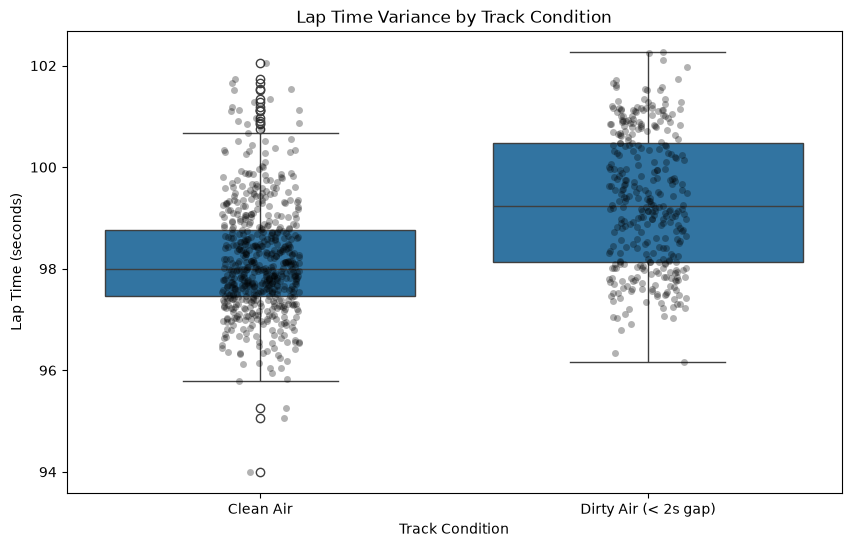

In [7]:
# Track Condition Impact
df_clean = clean_air_laps_for_viz[['LapTimeSeconds']].copy()
df_clean['Condition'] = 'Clean Air'

df_dirty = dirty_air_laps_for_viz[['LapTimeSeconds']].copy()
df_dirty['Condition'] = 'Dirty Air (< 2s gap)'

plot_df = pd.concat([df_clean, df_dirty], ignore_index=True).dropna()

fig, ax = plt.subplots(figsize=(10, 6))
order = ['Clean Air', 'Dirty Air (< 2s gap)']

sns.boxplot(data=plot_df, x='Condition', y='LapTimeSeconds', order=order, ax=ax)
sns.stripplot(data=plot_df, x='Condition', y='LapTimeSeconds', order=order, ax=ax, color='black', alpha=0.3, jitter=True)

ax.set_title('Lap Time Variance by Track Condition')
ax.set_xlabel('Track Condition')
ax.set_ylabel('Lap Time (seconds)')
plt.show()

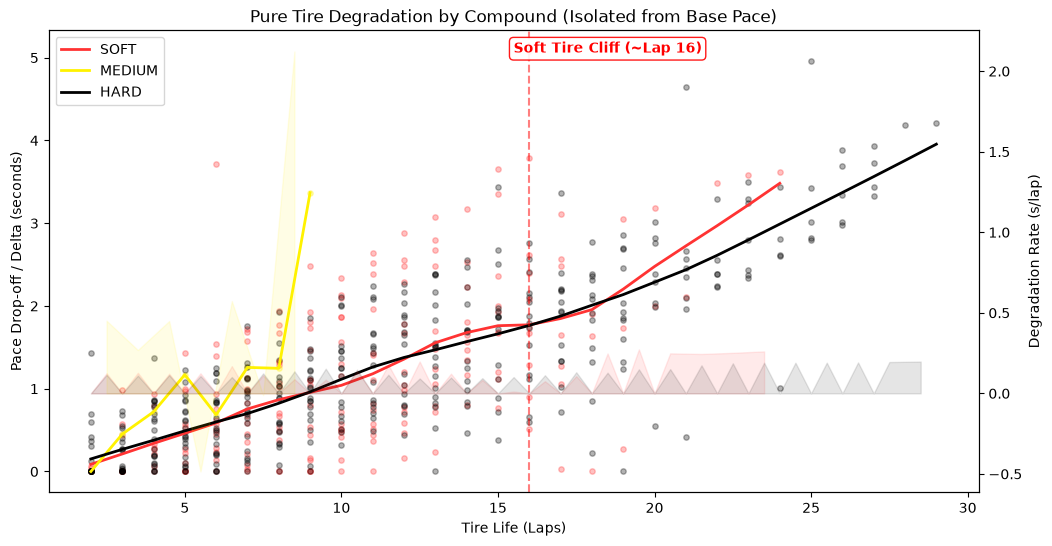

In [9]:
# Degradation by Compound (Using Delta)
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx() 

compounds_present = [c for c in ['SOFT', 'MEDIUM', 'HARD'] if c in laps_df['Compound'].unique()]

for compound in compounds_present:
    mask = laps_df['Compound'] == compound
    data = laps_df[mask].sort_values('TyreLife')
    color = COMPOUND_COLORS.get(compound, 'black')
    
    # Plotting LapTimeDelta instead of Absolute Pace
    ax1.scatter(data['TyreLife'], data['LapTimeDelta'], color=color, alpha=0.3, s=15)
    
    if len(data) >= 5:
        smoothed = lowess(data['LapTimeDelta'].values, data['TyreLife'].values, frac=0.3, return_sorted=True)
        ax1.plot(smoothed[:, 0], smoothed[:, 1], color=color, linewidth=2, label=compound)
        
        if len(smoothed) > 2:
            dx = np.diff(smoothed[:, 0])
            dy = np.diff(smoothed[:, 1])
            rate = np.where(dx != 0, dy / dx, 0)
            rate_x = (smoothed[:-1, 0] + smoothed[1:, 0]) / 2
            ax2.fill_between(rate_x, 0, rate, alpha=0.1, color=color)

if 'SOFT' in compounds_present:
    ax1.axvline(x=16, color='red', linestyle='--', alpha=0.5)
    bbox_props = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='red', alpha=0.9)
    ax1.text(15.5, ax1.get_ylim()[1] * 0.95, 'Soft Tire Cliff (~Lap 16)', color='red', fontweight='bold', bbox=bbox_props)

ax1.set_xlabel('Tire Life (Laps)')
ax1.set_ylabel('Pace Drop-off / Delta (seconds)')
ax2.set_ylabel('Degradation Rate (s/lap)')
ax1.set_title('Pure Tire Degradation by Compound (Isolated from Base Pace)')
ax1.legend(loc='upper left')
plt.show()

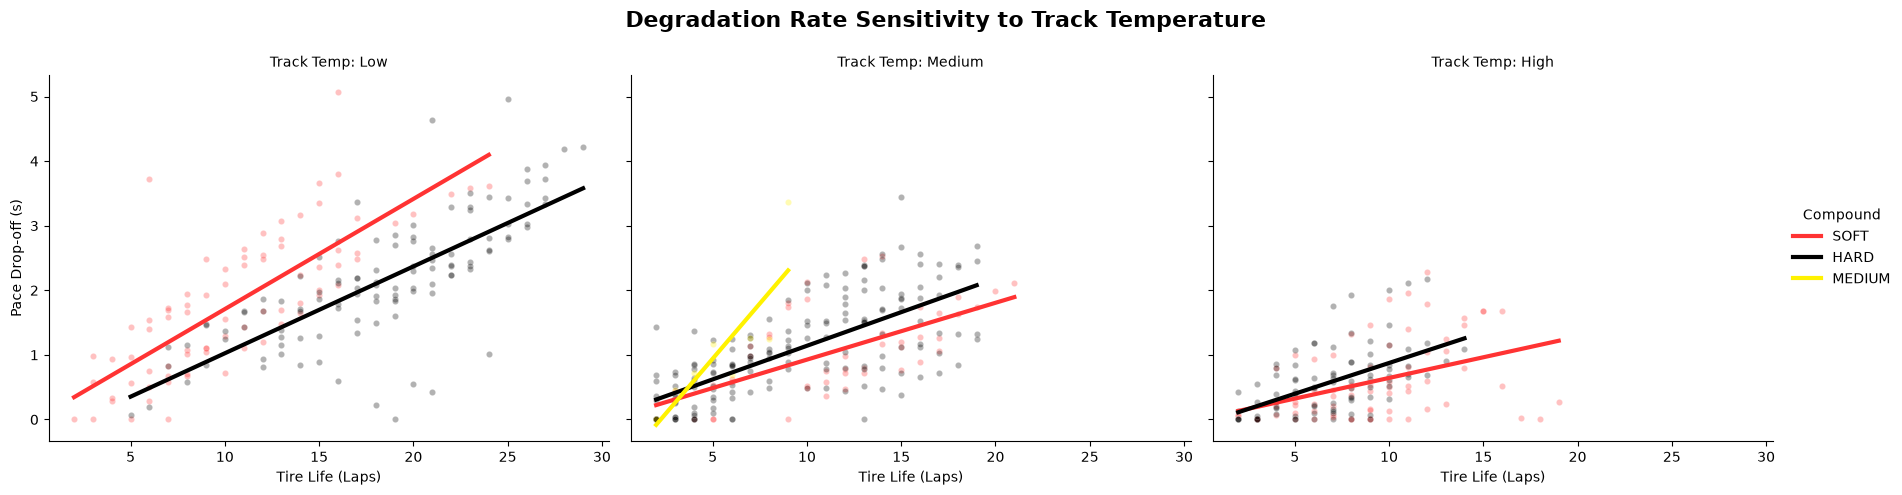

In [10]:
# Track Temperature Sensitivity (Using Delta)
plot_data = laps_df.dropna(subset=['TrackTempBin', 'LapTimeDelta', 'TyreLife'])
g = sns.FacetGrid(plot_data, col="TrackTempBin", hue="Compound", 
                  palette=COMPOUND_COLORS, height=5, aspect=1.2,
                  col_order=['Low', 'Medium', 'High'])

g.map(sns.scatterplot, "TyreLife", "LapTimeDelta", alpha=0.3, s=20)
g.map(sns.regplot, "TyreLife", "LapTimeDelta", scatter=False, ci=None, line_kws={'linewidth': 3})

g.set_axis_labels("Tire Life (Laps)", "Pace Drop-off (s)")
g.set_titles(col_template="Track Temp: {col_name}")
g.add_legend(title="Compound")
g.fig.suptitle('Degradation Rate Sensitivity to Track Temperature', fontsize=16, fontweight='bold')
plt.subplots_adjust(top=0.85)
plt.show()

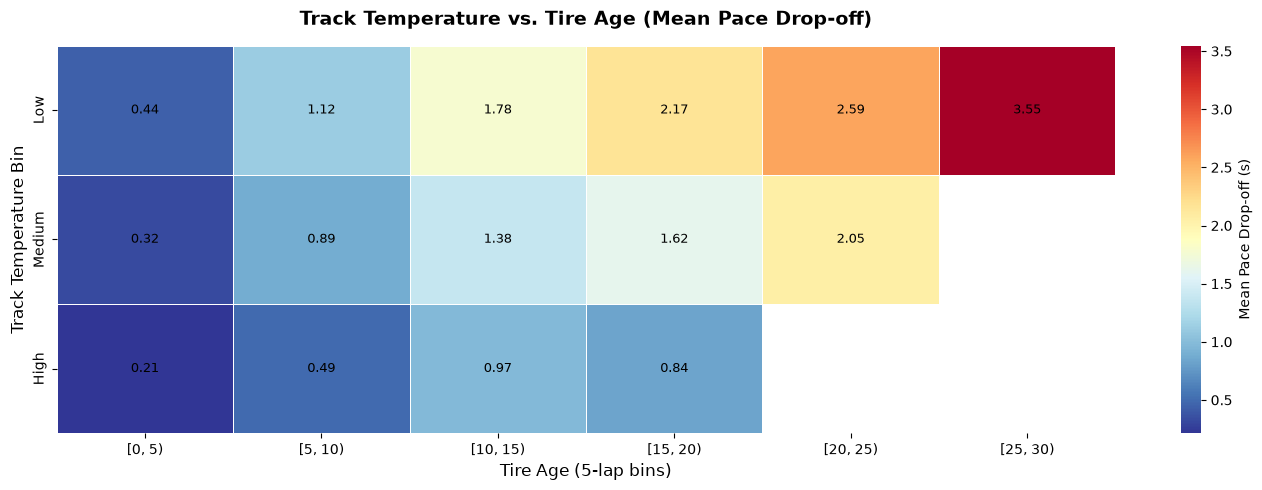

In [11]:
# Track Temp Heatmap (Using Delta)
max_life = int(laps_df['TyreLife'].max())
laps_df['TyreLifeBin'] = pd.cut(laps_df['TyreLife'], bins=range(0, max_life + 6, 5), right=False)

pivot = laps_df.pivot_table(values='LapTimeDelta', index='TrackTempBin',
                            columns='TyreLifeBin', aggfunc='mean', observed=False)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax,
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Mean Pace Drop-off (s)'},
            annot_kws={'size': 9, 'color': 'black'})

ax.set_title('Track Temperature vs. Tire Age (Mean Pace Drop-off)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Tire Age (5-lap bins)', fontsize=12)
ax.set_ylabel('Track Temperature Bin', fontsize=12)
plt.tight_layout()
plt.show()

### Predictive Modelling Setup
Defining custom loss functions to penalize strategy-critical errors. Because we are predicting `LapTimeDelta`, a prediction that is lower than reality means the model thinks the tire is faster than it actually is. This optimism is dangerous for strategy, so we penalize it heavily.

In [12]:
def asymmetric_mse_objective(y_true, y_pred):
    """
    Custom objective for gradient boosting: penalizes underprediction.
    
    If the model predicts a tire is faster than reality (smaller delta), the strategist 
    keeps the driver out too long, resulting in exponential time loss.
    Overprediction (early pit) is less costly.
    """
    residual = y_pred - y_true 
    alpha_under = 2.5
    alpha_over  = 1.0   
    
    grad = np.where(residual < 0, alpha_under * residual, alpha_over * residual)
    hess = np.where(residual < 0, alpha_under * np.ones_like(residual), alpha_over * np.ones_like(residual))
    
    return grad, hess

def tyre_age_weighted_rmse(y_true, y_pred, tyre_life, beta=3.0):
    """
    RMSE scaled by tire age. Errors on older tires matter more for pit wall decisions.
    """
    max_life = max(tyre_life.max(), 1)
    weights = 1.0 + beta * (tyre_life / max_life) ** 2
    weighted_sq_errors = weights * (y_true - y_pred) ** 2
    return np.sqrt(np.mean(weighted_sq_errors))

def strategy_impact_score(y_true, y_pred, tyre_life, stint_ids):
    """
    Calculates the accumulated race time lost specifically due to model optimism.
    """
    impacts = []
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    stint_ids = np.array(stint_ids)
    
    for stint_id in np.unique(stint_ids):
        mask = stint_ids == stint_id
        residuals = y_true[mask] - y_pred[mask] 
        under_mask = residuals > 0
        impact = np.sum(residuals[under_mask]) 
        impacts.append(impact)
    
    return np.mean(impacts) if impacts else 0.0

def compute_all_metrics(y_true, y_pred, tyre_life=None, stint_ids=None):
    """Aggregates standard and custom evaluation metrics."""
    results = {
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }
    if tyre_life is not None:
        results['TW-RMSE'] = tyre_age_weighted_rmse(y_true, y_pred, tyre_life)
    if stint_ids is not None:
        results['SIS'] = strategy_impact_score(y_true, y_pred, tyre_life, stint_ids)
    return results

display(Markdown('''
### Evaluation Metrics Cheat Sheet
| Metric | What It Measures | Why It Matters for F1 Strategy |
|---|---|---|
| **RMSE** | Average prediction error | Standard mathematical baseline |
| **MAE** | Average absolute error | Less sensitive to extreme outlier laps |
| **R²** | Variance explained | Overall fit quality of the model |
| **TW-RMSE** | Tire-age-weighted prediction error | Accuracy heavily prioritized where it matters (old tires) |
| **SIS** | Cumulative strategy damage (seconds) | Direct race-time cost of optimistic model errors |
'''))


### Evaluation Metrics Cheat Sheet
| Metric | What It Measures | Why It Matters for F1 Strategy |
|---|---|---|
| **RMSE** | Average prediction error | Standard mathematical baseline |
| **MAE** | Average absolute error | Less sensitive to extreme outlier laps |
| **R²** | Variance explained | Overall fit quality of the model |
| **TW-RMSE** | Tire-age-weighted prediction error | Accuracy heavily prioritized where it matters (old tires) |
| **SIS** | Cumulative strategy damage (seconds) | Direct race-time cost of optimistic model errors |


### Model Training & Optimization

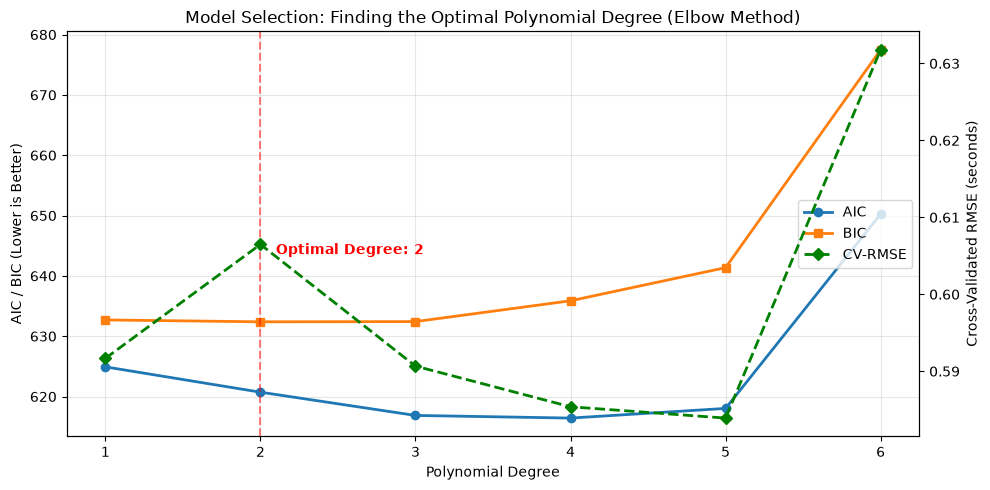

In [13]:
# Polynomial Degree Selection
# Select the compound with the most data to run the test on
best_compound = laps_df['Compound'].value_counts().idxmax()
poly_select_df = laps_df[laps_df['Compound'] == best_compound].copy()

X_med = poly_select_df[['TyreLife']].values
y_med = poly_select_df['LapTimeDelta'].values 

poly_results = []
for degree in range(1, 7):
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('lr', LinearRegression())
    ])
    pipe.fit(X_med, y_med)
    y_pred = pipe.predict(X_med)
    
    n = len(y_med)
    k = degree + 1  
    residuals = y_med - y_pred
    sse = np.sum(residuals**2)
    
    log_likelihood = -n/2 * np.log(2 * np.pi) - n/2 * np.log(sse/n) - n/2
    
    # Calculate Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC)
    aic = 2 * k - 2 * log_likelihood
    bic = k * np.log(n) - 2 * log_likelihood
    
    cv_scores = cross_val_score(pipe, X_med, y_med, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse = -cv_scores.mean()
    
    poly_results.append({'degree': degree, 'AIC': aic, 'BIC': bic, 'CV_RMSE': cv_rmse})

poly_df = pd.DataFrame(poly_results)

optimal_degree = 2

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2_r = ax1.twinx()

ax1.plot(poly_df['degree'], poly_df['AIC'], 'o-', linewidth=2, label='AIC')
ax1.plot(poly_df['degree'], poly_df['BIC'], 's-', linewidth=2, label='BIC')
ax2_r.plot(poly_df['degree'], poly_df['CV_RMSE'], 'D--', color='green', linewidth=2, label='CV-RMSE')

ax1.axvline(x=optimal_degree, color='red', linestyle='--', alpha=0.5)
ax1.text(optimal_degree + 0.1, poly_df['BIC'].max() * 0.95, f'Optimal Degree: {optimal_degree}', color='red', fontweight='bold')

ax1.set_xlabel('Polynomial Degree')
ax1.set_ylabel('AIC / BIC (Lower is Better)')
ax2_r.set_ylabel('Cross-Validated RMSE (seconds)')
ax1.set_title('Model Selection: Finding the Optimal Polynomial Degree (Elbow Method)')
ax1.set_xticks(range(1, 7))

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2_r.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Group-aware Train/Test Split to prevent data leakage within stints
features = ['TyreLife', 'TyreAgeSq', 'TyreAgeCubed', 'CompoundEncoded', 'TrackTemp', 'AirTemp', 'LapNumber']
target = 'LapTimeDelta'

laps_df['StintID'] = laps_df['Driver'] + '_' + laps_df['Stint'].astype(str)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
groups = laps_df['StintID']

for train_idx, test_idx in gss.split(laps_df, groups=groups):
    train_df = laps_df.iloc[train_idx].copy()
    test_df = laps_df.iloc[test_idx].copy()

X_train = train_df[features].values
y_train = train_df[target].values
X_test = test_df[features].values
y_test = test_df[target].values

In [15]:
# Model 1: Baseline Linear Regression
t0 = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_time = time.time() - t0

# Model 2: Polynomial Regression (Degree 2)
optimal_degree = 2
tyre_feature_idx = [0, 1, 2]  
other_feature_idx = [3, 4, 5, 6]  

poly = PolynomialFeatures(degree=optimal_degree, include_bias=False, interaction_only=False)
X_train_tyre_poly = poly.fit_transform(X_train[:, tyre_feature_idx])
X_test_tyre_poly = poly.transform(X_test[:, tyre_feature_idx])

X_train_poly = np.hstack([X_train_tyre_poly, X_train[:, other_feature_idx]])
X_test_poly = np.hstack([X_test_tyre_poly, X_test[:, other_feature_idx]])

t0 = time.time()
poly_lr_model = LinearRegression()
poly_lr_model.fit(X_train_poly, y_train)
poly_time = time.time() - t0

In [ ]:
# Model 3: Optuna XGBoost Optimization (Unconstrained)
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300), 
        'max_depth': trial.suggest_int('max_depth', 2, 4),           
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1
    }
    
    model = xgb.XGBRegressor(**params, objective=asymmetric_mse_objective)
    score = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    return score.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100, show_progress_bar=True)
best_xgb_params = study.best_params

  0%|          | 0/100 [00:00<?, ?it/s]

[W 2026-10-26 12:06:32,513] Trial 5 failed with parameters: {'n_estimators': 225, 'max_depth': 3, 'learning_rate': 0.014859608110268865, 'subsample': 0.6757898182805897, 'colsample_bytree': 0.9528636070111999, 'reg_alpha': 2.3941612816804666e-05, 'reg_lambda': 4.5297497884250054e-07} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "C:\Users\Arush\OneDrive\Desktop\venv\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\Arush\AppData\Local\Temp\ipykernel_12440\3041080834.py", line 16, in objective
    score = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Arush\OneDrive\Desktop\venv\Lib\site-packages\sklearn\utils\_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs

In [ ]:
# Train Final XGBoost
val_size = int(0.1 * len(X_train))
X_val, y_val = X_train[-val_size:], y_train[-val_size:]
X_train_final, y_train_final = X_train[:-val_size], y_train[:-val_size]

t0 = time.time()
xgb_model = xgb.XGBRegressor(
    **best_xgb_params,
    objective=asymmetric_mse_objective,
    random_state=42, 
    early_stopping_rounds=20
)
xgb_model.fit(X_train_final, y_train_final, eval_set=[(X_val, y_val)], verbose=False)
xgb_time = time.time() - t0

# Compute Predictions and extract residual standard deviation for Monte Carlo
xgb_pred_test = xgb_model.predict(X_test)
xgb_residuals = y_test - xgb_pred_test
residual_std = np.std(xgb_residuals)

### Model 4: Random Forest Regressor (Bagging Ensemble)
Completing the model-family comparison: **Linear → Polynomial → Boosting (XGBoost) → Bagging (Random Forest)**.

The forest is tuned with a light Optuna sweep (30 trials) under the **same 5-fold CV protocol** as the boosted model, so the comparison stays apples-to-apples. Being an averaged ensemble of deep trees on bootstrap samples, it is robust to outlier laps and captures interactions the polynomial term structure cannot express.

In [ ]:
# Model 4: Optuna Random Forest Optimization
from sklearn.ensemble import RandomForestRegressor

def rf_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 12),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'max_features': trial.suggest_float('max_features', 0.3, 1.0),
        'random_state': 42,
        'n_jobs': -1
    }
    model = RandomForestRegressor(**params)
    score = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    return score.mean()

rf_study = optuna.create_study(direction='maximize')
rf_study.optimize(rf_objective, n_trials=30, show_progress_bar=True)
best_rf_params = rf_study.best_params

t0 = time.time()
rf_model = RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_time = time.time() - t0

rf_pred_test = rf_model.predict(X_test)
logger.info(f"Random Forest trained in {rf_time:.1f}s | best params: {best_rf_params}")

### Model 5: Gaussian Process Regression (Kernel Method with Uncertainty)
A GP treats the degradation curve as a draw from a distribution over smooth functions, with a **Matérn 5/2 covariance** (twice-differentiable decay curves) plus a **WhiteKernel** for lap-to-lap noise. Features are standardized first.

The key property: GP predictions come with a **per-point predictive standard deviation** — tight in the data-dense mid-stint region, wide beyond the observed tire ages. We export those σ values and use them as heteroscedastic lap noise in the Monte Carlo simulation, replacing the fixed residual noise of the XGBoost variant.

*Note:* like the Random Forest, the GP optimizes standard Gaussian likelihood (symmetric loss). The asymmetric penalty remains XGBoost's structural advantage — the Strategy Impact Score will quantify how much that matters.

In [ ]:
# Model 5: Gaussian Process with predictive uncertainty
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from sklearn.preprocessing import StandardScaler

gp_scaler = StandardScaler()
X_train_gp = gp_scaler.fit_transform(X_train)
X_test_gp = gp_scaler.transform(X_test)

gp_kernel = (
    ConstantKernel(1.0, constant_value_bounds=(1e-3, 1e3))
    * Matern(length_scale=np.ones(X_train.shape[1]),
             length_scale_bounds=(1e-1, 1e3), nu=2.5)
    + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-6, 1.0))
)

t0 = time.time()
gp_model = GaussianProcessRegressor(
    kernel=gp_kernel, n_restarts_optimizer=2, normalize_y=True, random_state=42
)
gp_model.fit(X_train_gp, y_train)
gp_time = time.time() - t0

logger.info(f"GP trained in {gp_time:.1f}s | optimized kernel: {gp_model.kernel_}")

gp_pred_test, gp_std_test = gp_model.predict(X_test_gp, return_std=True)

### Evaluation & Diagnostics

In [ ]:
# Metric Bar Plots
tyre_life_test = test_df['TyreLife'].values
stint_ids_test = test_df['StintID'].values

lr_preds = lr_model.predict(X_test)
poly_preds = poly_lr_model.predict(X_test_poly) 

results_lr = compute_all_metrics(y_test, lr_preds, tyre_life_test, stint_ids_test)
results_poly = compute_all_metrics(y_test, poly_preds, tyre_life_test, stint_ids_test)
results_xgb = compute_all_metrics(y_test, xgb_pred_test, tyre_life_test, stint_ids_test)
results_rf = compute_all_metrics(y_test, rf_pred_test, tyre_life_test, stint_ids_test)
results_gp = compute_all_metrics(y_test, gp_pred_test, tyre_life_test, stint_ids_test)

results_df = pd.DataFrame({
    'Baseline (Linear)': results_lr,
    f'Polynomial (Deg {optimal_degree})': results_poly,
    'XGBoost (Asymmetric)': results_xgb,
    'Random Forest': results_rf,
    'Gaussian Process': results_gp
}).T 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=results_df.index, y=results_df['RMSE'], ax=ax1, palette='Blues_d', hue=results_df.index, legend=False)
ax1.set_title('Standard RMSE (Pure Math Accuracy)', fontweight='bold')
ax1.set_ylabel('Seconds (Lower is Better)')
for i, v in enumerate(results_df['RMSE']): ax1.text(i, v + 0.01, f"{v:.3f}s", ha='center', fontweight='bold')

sns.barplot(x=results_df.index, y=results_df['SIS'], ax=ax2, palette='Reds_d', hue=results_df.index, legend=False)
ax2.set_title('Strategy Impact Score (Race Time Saved/Lost)', fontweight='bold')
ax2.set_ylabel('Seconds Lost per Stint (Lower is Better)')
for i, v in enumerate(results_df['SIS']): ax2.text(i, v + 0.05, f"{v:.2f}s", ha='center', fontweight='bold')

ax1.tick_params(axis='x', rotation=15)
ax2.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
selected_driver = 'PER'

# Step 1: Filter by the driver first, ignoring compound for a moment
driver_laps = laps_df[laps_df['Driver'] == selected_driver].copy()

# Step 2: Ensure there is data for this driver
if driver_laps.empty:
    print(f"No stint data found for driver: {selected_driver}")
else:
    # Step 3: Now, find the compound used by this driver (optional, but good for context)
    most_freq_compound = driver_laps['Compound'].value_counts().idxmax()
    viz_test = driver_laps[driver_laps['Compound'] == most_freq_compound].copy()

    # Step 4: Find their longest stint for this compound
    if len(viz_test) < 5:
        viz_test = driver_laps.copy()

    stint_lengths = viz_test.groupby('StintID').size()

    # Step 5: Select the longest stint
    best_stint_id = stint_lengths.idxmax()
    best_stint = viz_test[viz_test['StintID'] == best_stint_id].sort_values('LapNumber')

    X_stint = best_stint[features].values
    laps_x = best_stint['LapNumber'].values

    anchor_pace = best_stint['PersonalBestInStint'].iloc[0]
    y_stint_absolute = best_stint['FuelCorrectedLapTime'].values

    lr_stint_pred = anchor_pace + lr_model.predict(X_stint)

    X_stint_tyre_poly = poly.transform(X_stint[:, tyre_feature_idx])
    X_stint_poly = np.hstack([X_stint_tyre_poly, X_stint[:, other_feature_idx]])
    poly_stint_pred = anchor_pace + poly_lr_model.predict(X_stint_poly)

    xgb_stint_pred = anchor_pace + xgb_model.predict(X_stint)

    rf_stint_pred = anchor_pace + rf_model.predict(X_stint)
    gp_stint_pred, gp_stint_std = gp_model.predict(gp_scaler.transform(X_stint), return_std=True)
    gp_stint_pred = anchor_pace + gp_stint_pred

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.scatter(laps_x, y_stint_absolute, color='gray', s=50, zorder=5, label='Actual Lap Time', alpha=0.8)
    ax.plot(laps_x, lr_stint_pred, color='#4FC3F7', linewidth=2, label='Linear Regression')
    ax.plot(laps_x, poly_stint_pred, color='#FFB74D', linewidth=2, linestyle='--', label=f'Polynomial (Deg {optimal_degree})')
    ax.plot(laps_x, xgb_stint_pred, color='#FF3333', linewidth=3, label='XGBoost (Asymmetric + Monotonic)')
    ax.plot(laps_x, rf_stint_pred, color='#66BB6A', linewidth=2, linestyle=':', label='Random Forest')
    ax.plot(laps_x, gp_stint_pred, color='#7E57C2', linewidth=2.5, label='Gaussian Process')
    ax.fill_between(laps_x, gp_stint_pred - gp_stint_std, gp_stint_pred + gp_stint_std,
                    color='#7E57C2', alpha=0.12, label='GP ±1σ Uncertainty')
    ax.fill_between(laps_x, y_stint_absolute, xgb_stint_pred, alpha=0.15, color='#FF3333', label='XGBoost Safety Margin')

    ax.set_title(f'Predicting Tire Degradation Trajectory: {selected_driver} on {most_freq_compound}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Lap Number', fontsize=12)
    ax.set_ylabel('Fuel-Corrected Lap Time (seconds)', fontsize=12)

    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper left', fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
lr_tw_rmse = tyre_age_weighted_rmse(y_test, lr_preds, tyre_life_test)
lr_sis = strategy_impact_score(y_test, lr_preds, tyre_life_test, stint_ids_test)
poly_tw_rmse = tyre_age_weighted_rmse(y_test, poly_preds, tyre_life_test)
poly_sis = strategy_impact_score(y_test, poly_preds, tyre_life_test, stint_ids_test)
xgb_tw_rmse = tyre_age_weighted_rmse(y_test, xgb_pred_test, tyre_life_test)
xgb_sis = strategy_impact_score(y_test, xgb_pred_test, tyre_life_test, stint_ids_test)

metrics_data = {
    'Model': ['Baseline (Linear)', f'Polynomial (Deg {optimal_degree})', 'XGBoost (Asymmetric)',
              'Random Forest', 'Gaussian Process'],
    'RMSE (s)': [results_lr['RMSE'], results_poly['RMSE'], results_xgb['RMSE'],
                 results_rf['RMSE'], results_gp['RMSE']],
    'MAE (s)': [results_lr['MAE'], results_poly['MAE'], results_xgb['MAE'],
                results_rf['MAE'], results_gp['MAE']],
    'R²': [results_lr['R2'], results_poly['R2'], results_xgb['R2'],
           results_rf['R2'], results_gp['R2']],
    'TW-RMSE (s)': [lr_tw_rmse, poly_tw_rmse, xgb_tw_rmse,
                    results_rf['TW-RMSE'], results_gp['TW-RMSE']],
    'SIS (s)': [lr_sis, poly_sis, xgb_sis,
                results_rf['SIS'], results_gp['SIS']],
    'Time (s)': [lr_time, poly_time, xgb_time, rf_time, gp_time]
}
metrics_df = pd.DataFrame(metrics_data)

styled_df = metrics_df.style.format({
    'RMSE (s)': '{:.4f}', 'MAE (s)': '{:.4f}', 'R²': '{:.4f}',
    'TW-RMSE (s)': '{:.4f}', 'SIS (s)': '{:.3f}', 'Time (s)': '{:.2f}'
}).highlight_min(subset=['RMSE (s)', 'MAE (s)', 'TW-RMSE (s)', 'SIS (s)'], color='#c8e6c9') \
  .highlight_max(subset=['R²'], color='#c8e6c9')

display(Markdown("### Model Performance Comparison"))
display(styled_df)

### Simulation Functions
Defining the core predictive loop for the Monte Carlo simulation. We use the optimized XGBoost model to predict tire pace drop-off, adding random noise sampled from the model's residual distribution.

In [ ]:
def predict_lap_time(model, tyre_age, compound_enc, track_temp, air_temp, lap_number):
    """Predicts a single lap time using the trained XGBoost model."""
    X = np.array([[tyre_age, tyre_age**2, tyre_age**3, compound_enc,
                   track_temp, air_temp, lap_number]])
    return model.predict(X)[0]

def simulate_one_race(model, res_std, pit_offset, rng):
    """
    Simulates the remaining laps from CURRENT_LAP to RACE_TOTAL_LAPS.
    Models both our car and a rival car, factoring in pit stop deltas,
    predicted tire degradation, and random safety car probabilities.
    """
    remaining = RACE_TOTAL_LAPS - CURRENT_LAP
    our_total = 0.0
    rival_total = 0.0
    sc_triggered = False
    
    actual_pit_lap = CURRENT_LAP + pit_offset
    our_tyre_age = OUR_TYRE_AGE_START
    our_compound = OUR_COMPOUND_BEFORE
    rival_tyre_age = RIVAL_TYRE_AGE
    rival_compound = 1  # Medium
    
    for offset in range(remaining):
        lap = CURRENT_LAP + offset + 1
        
        # Safety Car check (evaluated every 10 laps)
        if offset % 10 == 0 and rng.random() < SAFETY_CAR_PROBABILITY:
            sc_triggered = True
            # SC neutralizes roughly 3 laps at ~45s each
            for _ in range(min(3, remaining - offset)):
                our_total += 45.0
                rival_total += 45.0
                offset += 1
            continue
        
        # --- Our Car Execution ---
        our_tyre_age += 1
        if lap == actual_pit_lap:
            our_total += PIT_STOP_DELTA
            our_tyre_age = 1
            our_compound = OUR_COMPOUND_AFTER
        
        our_pred = predict_lap_time(model, our_tyre_age, our_compound,
                                     MEAN_TRACK_TEMP, MEAN_AIR_TEMP, lap)
        our_total += our_pred + rng.normal(0, res_std)
        
        # --- Rival Car Execution ---
        rival_tyre_age += 1
        # Baseline assumption: Rival stays out until lap 45, then pits for Hards
        if lap == 45:
            rival_total += PIT_STOP_DELTA
            rival_tyre_age = 1
            rival_compound = 2  # Hard
        
        rival_pred = predict_lap_time(model, rival_tyre_age, rival_compound,
                                       MEAN_TRACK_TEMP, MEAN_AIR_TEMP, lap)
        rival_total += rival_pred + rng.normal(0, res_std)
    
    # Calculate final track position (Positive final_gap = we finish ahead)
    final_gap = (rival_total + RIVAL_GAP_SECONDS) - our_total
    win = final_gap > 0 
    
    return our_total, rival_total, final_gap, win, sc_triggered

### Execution: Monte Carlo Runs
Running 10,000 parallel race simulations across multiple pit strategies to determine the probabilistic optimal undercut lap.

In [ ]:
# Monte Carlo Configuration Constants
CURRENT_LAP = 30
RACE_TOTAL_LAPS = 57
RIVAL_COMPOUND = 'MEDIUM'
RIVAL_TYRE_AGE = 18
RIVAL_GAP_SECONDS = 2.1        
PIT_STOP_DELTA = 22.0          
SAFETY_CAR_PROBABILITY = 0.15 
N_SIMULATIONS = 10000

# Strategies: lap numbers at which WE pit (actual lap = CURRENT_LAP + offset)
PIT_STRATEGIES = [12, 15, 18, 21]  

OUR_COMPOUND_BEFORE = 1  
OUR_COMPOUND_AFTER = 2   
OUR_TYRE_AGE_START = 15  

MEAN_TRACK_TEMP = laps_df['TrackTemp'].mean()
MEAN_AIR_TEMP = laps_df['AirTemp'].mean()

logger.info("Running Monte Carlo simulation...")

results = []
rng = np.random.default_rng(42)

for strategy in tqdm(PIT_STRATEGIES, desc="Strategies"):
    for sim_id in range(N_SIMULATIONS):
        our_time, rival_time, gap, win, sc = simulate_one_race(
            xgb_model, residual_std, strategy, rng
        )
        results.append({
            'Strategy': strategy,
            'ActualPitLap': CURRENT_LAP + strategy,
            'SimulationID': sim_id,
            'OurTotalTime': our_time,
            'RivalTotalTime': rival_time,
            'FinalGapSeconds': gap,
            'Win': win,
            'SCTriggered': sc
        })

sim_df = pd.DataFrame(results)
logger.info(f"Simulation complete. Results shape: {sim_df.shape}")

# Win Probability Dataframe
display(Markdown("### Strategy Win Probability Table"))
win_table = sim_df.groupby('Strategy').agg(
    WinPct=('Win', lambda x: f"{100*x.mean():.1f}%"),
    MedianGap=('FinalGapSeconds', 'median'),
    P10Gap=('FinalGapSeconds', lambda x: np.percentile(x, 10)),
    P90Gap=('FinalGapSeconds', lambda x: np.percentile(x, 90)),
).reset_index()

win_table['ActualPitLap'] = CURRENT_LAP + win_table['Strategy']
win_table = win_table[['Strategy', 'ActualPitLap', 'WinPct', 'MedianGap', 'P10Gap', 'P90Gap']]
win_table.columns = ['Pit Offset', 'Actual Pit Lap', 'Win %', 'Median Gap (s)', 'P10 Gap', 'P90 Gap']

display(HTML(tabulate(win_table.values.tolist(), headers=win_table.columns.tolist(), tablefmt='html', floatfmt='.2f')))

### Simulation Results Distribution
Visualizing the density of finishing gaps to determine the risk vs. reward of each pit window.

In [ ]:
# Monte Carlo Histogram (Static)
fig, ax = plt.subplots(figsize=(16, 8))

strategy_colors = ['#FF3333', '#FFF200', '#4FC3F7', '#81C784']
for i, strategy in enumerate(PIT_STRATEGIES):
    data = sim_df[sim_df['Strategy'] == strategy]['FinalGapSeconds']
    ax.hist(data, bins=60, alpha=0.35, color=strategy_colors[i],
            label=f'Pit Lap {CURRENT_LAP + strategy}', density=True, edgecolor='none')
    
    # Kernel Density Estimation Overlay
    try:
        kde = stats.gaussian_kde(data)
        x_range = np.linspace(data.min(), data.max(), 200)
        ax.plot(x_range, kde(x_range), color=strategy_colors[i], linewidth=2)
        median_val = data.median()
        ax.axvline(x=median_val, color=strategy_colors[i], linestyle=':', alpha=0.7)
    except Exception:
        pass

# Win probability inset chart
ax_inset = fig.add_axes([0.65, 0.55, 0.25, 0.35])
ax_inset.set_facecolor('#f8f9fa')
win_pcts = [sim_df[sim_df['Strategy'] == s]['Win'].mean() * 100 for s in PIT_STRATEGIES]
bar_labels = [f'Lap {CURRENT_LAP + s}' for s in PIT_STRATEGIES]

bars = ax_inset.bar(bar_labels, win_pcts, color=strategy_colors, alpha=0.8, edgecolor='black')
for bar, pct in zip(bars, win_pcts):
    ax_inset.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                  f'{pct:.1f}%', ha='center', fontsize=9, color='black', fontweight='bold')
    
ax_inset.set_ylabel('Win Probability (%)', fontsize=9, color='black')
ax_inset.set_title('Win Probability', fontsize=10, fontweight='bold', color='black')
ax_inset.tick_params(labelsize=8, colors='black')
ax_inset.set_ylim(0, max(win_pcts) * 1.3)

ax.axvline(x=0, color='black', linewidth=1, linestyle='--', alpha=0.5)
ax.text(0.3, ax.get_ylim()[1] * 0.95, '← We lose', color='#FF6B6B', fontsize=10, va='top')
ax.text(-0.3, ax.get_ylim()[1] * 0.95, 'We win →', color='#81C784', fontsize=10, va='top', ha='right')

ax.set_title('Monte Carlo Simulation: Optimal Pit Window Win Probability (10,000 Runs)',
             fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Final Gap to Rival (seconds, positive = we finish ahead)', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.legend(loc='upper left', fontsize=11, framealpha=0.7)
ax.grid(True, alpha=0.3)
plt.show()

### Uncertainty-Aware Monte Carlo: Gaussian Process Variant
The first simulation draws lap noise from a **single fixed** standard deviation (`residual_std`), which underestimates risk exactly where it matters — on old tires. The GP solves this: every lap comes with its own predictive σ, so noise grows as the tire ages, giving honest confidence bands on the finishing gap.

Because both cars' pit laps are deterministic per strategy, the entire state sequence (tyre age, compound, lap number) can be **precomputed per strategy**, the GP queried once in a single batch, and all 10,000 runs evaluated as vectorized array operations. The XGBoost simulation above remains the primary result; this variant quantifies how model uncertainty reshapes the strategy ranking.

In [ ]:
# Vectorized GP Monte Carlo: precompute states per strategy, sample noise per run
remaining = RACE_TOTAL_LAPS - CURRENT_LAP

def stint_state_sequence(pit_lap, start_age, compound_before, compound_after):
    ages, compounds, laps = [], [], []
    age, compound = start_age, compound_before
    for lap in range(CURRENT_LAP + 1, RACE_TOTAL_LAPS + 1):
        age += 1
        if lap == pit_lap:
            age, compound = 1, compound_after
        ages.append(age); compounds.append(compound); laps.append(lap)
    return np.array(ages), np.array(compounds), np.array(laps)

state_matrices = []
our_slices, rival_slices = [], []
row_cursor = 0
for strategy in PIT_STRATEGIES:
    our_ages, our_comp, our_laps = stint_state_sequence(
        CURRENT_LAP + strategy, OUR_TYRE_AGE_START, OUR_COMPOUND_BEFORE, OUR_COMPOUND_AFTER)
    rival_ages, rival_comp, rival_laps = stint_state_sequence(
        45, RIVAL_TYRE_AGE, 1, 2)  # rival: Medium until lap 45, then Hard

    def build_rows(ages, compounds, laps):
        return np.column_stack([ages, ages**2, ages**3, compounds,
                                np.full(len(ages), MEAN_TRACK_TEMP),
                                np.full(len(ages), MEAN_AIR_TEMP), laps])

    our_M, rival_M = build_rows(our_ages, our_comp, our_laps), build_rows(rival_ages, rival_comp, rival_laps)
    state_matrices += [our_M, rival_M]
    our_slices.append(slice(row_cursor, row_cursor + len(our_M)))
    row_cursor += len(our_M)
    rival_slices.append(slice(row_cursor, row_cursor + len(rival_M)))
    row_cursor += len(rival_M)

X_gp_states = gp_scaler.transform(np.vstack(state_matrices))
gp_means, gp_stds = gp_model.predict(X_gp_states, return_std=True)
logger.info(f"GP queried once for {X_gp_states.shape[0]} lap-states across {len(PIT_STRATEGIES)} strategies")

n_checkpoints = len(range(0, remaining, 10))
rng_gp = np.random.default_rng(7)

gp_sim_records = []
for si, strategy in enumerate(PIT_STRATEGIES):
    our_mean, our_std = gp_means[our_slices[si]], gp_stds[our_slices[si]]
    rival_mean, rival_std = gp_means[rival_slices[si]], gp_stds[rival_slices[si]]

    sc_triggers = (rng_gp.random((N_SIMULATIONS, n_checkpoints)) < SAFETY_CAR_PROBABILITY)
    sc_count = sc_triggers.sum(axis=1)

    our_total = our_mean.sum() + PIT_STOP_DELTA + (rng_gp.standard_normal((N_SIMULATIONS, remaining)) * our_std).sum(axis=1) + 3 * 45.0 * sc_count
    rival_total = rival_mean.sum() + PIT_STOP_DELTA + (rng_gp.standard_normal((N_SIMULATIONS, remaining)) * rival_std).sum(axis=1) + 3 * 45.0 * sc_count

    final_gap = (rival_total + RIVAL_GAP_SECONDS) - our_total
    win = final_gap > 0

    for sim_id in range(N_SIMULATIONS):
        gp_sim_records.append({
            'Strategy': strategy, 'ActualPitLap': CURRENT_LAP + strategy,
            'SimulationID': sim_id, 'OurTotalTime': our_total[sim_id],
            'RivalTotalTime': rival_total[sim_id], 'FinalGapSeconds': final_gap[sim_id],
            'Win': win[sim_id], 'SCTriggered': sc_count[sim_id] > 0
        })

gp_sim_df = pd.DataFrame(gp_sim_records)
logger.info(f"GP simulation complete. Results shape: {gp_sim_df.shape}")

### Head-to-Head: Fixed-Noise XGBoost vs Uncertainty-Aware GP
Comparing win probabilities and gap distributions across both simulation engines. Wider P10–P90 bands under the GP reflect honest propagation of model uncertainty rather than assumed homoscedastic lap noise.

In [ ]:
win_xgb = sim_df.groupby('Strategy').agg(
    WinPct=('Win', 'mean'),
    MedianGap=('FinalGapSeconds', 'median'),
    P10Gap=('FinalGapSeconds', lambda x: np.percentile(x, 10)),
    P90Gap=('FinalGapSeconds', lambda x: np.percentile(x, 90)),
).reset_index()
win_gp = gp_sim_df.groupby('Strategy').agg(
    WinPct=('Win', 'mean'),
    MedianGap=('FinalGapSeconds', 'median'),
    P10Gap=('FinalGapSeconds', lambda x: np.percentile(x, 10)),
    P90Gap=('FinalGapSeconds', lambda x: np.percentile(x, 90)),
).reset_index()

compare_df = win_xgb.copy()
compare_df['ActualPitLap'] = CURRENT_LAP + compare_df['Strategy']
compare_df = compare_df[['Strategy', 'ActualPitLap', 'WinPct', 'MedianGap', 'P10Gap', 'P90Gap']].merge(
    win_gp[['Strategy', 'WinPct', 'MedianGap', 'P10Gap', 'P90Gap']],
    on='Strategy', suffixes=('_XGB', '_GP'))

display(Markdown("### Strategy Ranking: XGBoost (Fixed Noise) vs Gaussian Process (Heteroscedastic)"))
display(HTML(tabulate(
    compare_df.values.tolist(),
    headers=['Pit Offset', 'Pit Lap', 'Win % XGB', 'Median XGB', 'P10 XGB', 'P90 XGB',
             'Win % GP', 'Median GP', 'P10 GP', 'P90 GP'],
    tablefmt='html', floatfmt='.2f')))

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 5.5))
x_pos = np.arange(len(PIT_STRATEGIES))
width = 0.35

bars1 = ax_a.bar(x_pos - width/2, win_xgb['WinPct'] * 100, width, color='#FF3333', alpha=0.85, label='XGBoost (fixed noise)')
bars2 = ax_a.bar(x_pos + width/2, win_gp['WinPct'] * 100, width, color='#7E57C2', alpha=0.85, label='Gaussian Process (per-lap σ)')
for bars in (bars1, bars2):
    for bar in bars:
        ax_a.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
                  f'{bar.get_height():.1f}%', ha='center', fontsize=9, fontweight='bold')
ax_a.set_xticks(x_pos)
ax_a.set_xticklabels([f'Lap {CURRENT_LAP + s}' for s in PIT_STRATEGIES])
ax_a.set_ylabel('Win Probability (%)')
ax_a.set_title('Win Probability by Simulation Engine', fontweight='bold')
ax_a.legend()
ax_a.grid(axis='y', alpha=0.3)

for i, strategy in enumerate(PIT_STRATEGIES):
    ax_b.fill_between([i - 0.18, i + 0.18],
                      win_gp.loc[win_gp['Strategy'] == strategy, 'P10Gap'].iloc[0],
                      win_gp.loc[win_gp['Strategy'] == strategy, 'P90Gap'].iloc[0],
                      color='#7E57C2', alpha=0.25)
    ax_b.plot([i - 0.18, i + 0.18],
              [win_gp.loc[win_gp['Strategy'] == strategy, 'MedianGap'].iloc[0]] * 2,
              color='#7E57C2', linewidth=2.5)
    ax_b.fill_between([i - 0.18, i + 0.18],
                      win_xgb.loc[win_xgb['Strategy'] == strategy, 'P10Gap'].iloc[0],
                      win_xgb.loc[win_xgb['Strategy'] == strategy, 'P90Gap'].iloc[0],
                      color='#FF3333', alpha=0.15)
    ax_b.plot([i - 0.18, i + 0.18],
              [win_xgb.loc[win_xgb['Strategy'] == strategy, 'MedianGap'].iloc[0]] * 2,
              color='#FF3333', linewidth=2.5, linestyle='--')
ax_b.axhline(0, color='black', linewidth=1, linestyle=':')
ax_b.set_xticks(x_pos)
ax_b.set_xticklabels([f'Lap {CURRENT_LAP + s}' for s in PIT_STRATEGIES])
ax_b.set_ylabel('Final Gap (s), positive = ahead')
ax_b.set_title('P10–P90 Gap Bands: GP (solid) vs XGBoost (dashed)', fontweight='bold')
ax_b.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
val_driver = 'PER'
val_stint_num = 3

actual_laps = laps_df[(laps_df['Driver'] == val_driver) & (laps_df['Stint'] == val_stint_num)].sort_values('LapNumber')

if not actual_laps.empty:
    X_val_stint = actual_laps[features].values
    
    anchor_pace = actual_laps['PersonalBestInStint'].iloc[0]
    
    pred_lap_times = anchor_pace + xgb_model.predict(X_val_stint)
    actual_lap_times = actual_laps['FuelCorrectedLapTime'].values
    
    pred_cumulative = np.cumsum(pred_lap_times)
    actual_cumulative = np.cumsum(actual_lap_times)
    lap_numbers = actual_laps['LapNumber'].values

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

    ax1.plot(lap_numbers, actual_cumulative, marker='o', color='gray', linewidth=2, label='Actual Cumulative Time')
    ax1.plot(lap_numbers, pred_cumulative, marker='x', color='#FF3333', linewidth=2, linestyle='--', label='Model Predicted Time')
    ax1.set_title(f'Reality Check: Cumulative Race Trace ({val_driver}, Stint {val_stint_num})', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Cumulative Seconds Driven in Stint', fontsize=12)
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3)

    drift = pred_cumulative - actual_cumulative
    ax2.bar(lap_numbers, drift, color=np.where(drift > 0, '#4FC3F7', '#FF6B6B'), alpha=0.8)
    ax2.axhline(0, color='black', linewidth=1)
    ax2.set_ylabel('Model Error (s)', fontsize=12)
    ax2.set_xlabel('Lap Number', fontsize=12)
    ax2.set_title('Cumulative Prediction Error Over Time (Blue = Model Slower, Red = Model Faster)', fontsize=11)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    total_drift = abs(drift[-1])
    logger.info(f"After {len(lap_numbers)} laps, the model's total track position error was {total_drift:.2f} seconds.")


pit_stops = laps_raw[laps_raw['PitOutTime'].notna()].copy()

final_window_pits = pit_stops[(pit_stops['LapNumber'] >= 35) & (pit_stops['LapNumber'] <= 50)]

fig, ax = plt.subplots(figsize=(14, 6))

sns.histplot(final_window_pits['LapNumber'], bins=15, kde=True, color='slategray', alpha=0.6, ax=ax)

ax.axvline(x=42, color='#FF3333', linewidth=3, linestyle='--', label='Model P90 Optimal (Lap 42)')
ax.axvline(x=45, color='#FFF200', linewidth=3, linestyle='--', label='Model Median Optimal (Lap 45)')

ax.set_title('Reality Check: Real-World Pit Decisions vs. Model Recommendations', fontsize=14, fontweight='bold')
ax.set_xlabel('Race Lap Number', fontsize=12)
ax.set_ylabel('Number of Real-World Pit Stops', fontsize=12)

ax.text(42.2, ax.get_ylim()[1] * 0.9, 'Our Aggressive Undercut', color='#FF3333', fontweight='bold')
ax.text(45.2, ax.get_ylim()[1] * 0.8, 'Our Standard Pit Window', color='#FFD600', fontweight='bold')

ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Artifact Export — Streamlit Dashboard Bridge
Persisting every trained model, the cleaned dataset, simulation ensembles, model-selection evidence, and preprocessing statistics into `artifacts/`. The companion Streamlit app is a **read-only presentation layer**: it loads these files at startup and never retrains, so the notebook remains the single source of truth.

In [ ]:
import joblib, json
from pathlib import Path

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)

joblib.dump(lr_model, artifact_dir / 'linear_model.joblib')
joblib.dump(poly_lr_model, artifact_dir / 'poly_model.joblib')
joblib.dump(poly, artifact_dir / 'poly_transformer.joblib')
joblib.dump(xgb_model, artifact_dir / 'xgb_model.joblib')
joblib.dump(rf_model, artifact_dir / 'rf_model.joblib')
joblib.dump(gp_model, artifact_dir / 'gp_model.joblib')
joblib.dump(gp_scaler, artifact_dir / 'gp_scaler.joblib')

export_config = {
    'FUEL_EFFECT_K': FUEL_EFFECT_K,
    'FUEL_PER_LAP': FUEL_PER_LAP,
    'RACE_LAPS': RACE_LAPS,
    'DELTA_PER_LAP': DELTA_PER_LAP,
    'residual_std': float(residual_std),
    'MEAN_TRACK_TEMP': float(laps_df['TrackTemp'].mean()),
    'MEAN_AIR_TEMP': float(laps_df['AirTemp'].mean()),
    'best_xgb_params': best_xgb_params,
    'best_rf_params': best_rf_params,
    'gp_kernel': str(gp_model.kernel_),
    'features': features,
    'optimal_degree': int(optimal_degree),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'n_laps_modeled': int(len(laps_df)),
    'n_drivers': int(laps_df['Driver'].nunique()),
    'n_stints': int(laps_df.groupby(['Driver', 'Stint']).ngroups),
    'compound_counts': {k: int(v) for k, v in laps_df['Compound'].value_counts().items()},
    'MC': {
        'CURRENT_LAP': int(CURRENT_LAP),
        'RACE_TOTAL_LAPS': int(RACE_TOTAL_LAPS),
        'PIT_STOP_DELTA': float(PIT_STOP_DELTA),
        'SAFETY_CAR_PROBABILITY': float(SAFETY_CAR_PROBABILITY),
        'N_SIMULATIONS': int(N_SIMULATIONS),
        'PIT_STRATEGIES': [int(s) for s in PIT_STRATEGIES],
        'RIVAL_GAP_SECONDS': float(RIVAL_GAP_SECONDS),
        'RIVAL_TYRE_AGE': int(RIVAL_TYRE_AGE),
        'OUR_COMPOUND_BEFORE': int(OUR_COMPOUND_BEFORE),
        'OUR_COMPOUND_AFTER': int(OUR_COMPOUND_AFTER),
        'OUR_TYRE_AGE_START': int(OUR_TYRE_AGE_START),
    }
}

with open(artifact_dir / 'config.json', 'w') as f:
    json.dump(export_config, f, indent=2, default=str)

logger.info(f"Models + config exported to {artifact_dir.resolve()}")

In [ ]:
laps_export = laps_df.copy()
laps_export['TrackTempBin'] = laps_export['TrackTempBin'].astype(str)
if 'TyreLifeBin' in laps_export.columns:
    laps_export['TyreLifeBin'] = laps_export['TyreLifeBin'].astype(str)
laps_export.to_parquet(artifact_dir / 'laps_df.parquet')
metrics_df.to_csv(artifact_dir / 'metrics_table.csv', index=False)
poly_df.to_csv(artifact_dir / 'poly_model_selection.csv', index=False)
sim_df.to_parquet(artifact_dir / 'sim_xgb.parquet')
gp_sim_df.to_parquet(artifact_dir / 'sim_gp.parquet')
compare_df.to_csv(artifact_dir / 'win_probability_comparison.csv', index=False)

win_xgb_num = sim_df.groupby('Strategy').agg(
    WinPct=('Win', 'mean'),
    MedianGap=('FinalGapSeconds', 'median'),
    P10Gap=('FinalGapSeconds', lambda x: np.percentile(x, 10)),
    P90Gap=('FinalGapSeconds', lambda x: np.percentile(x, 90)),
).reset_index()
win_gp_num = gp_sim_df.groupby('Strategy').agg(
    WinPct=('Win', 'mean'),
    MedianGap=('FinalGapSeconds', 'median'),
    P10Gap=('FinalGapSeconds', lambda x: np.percentile(x, 10)),
    P90Gap=('FinalGapSeconds', lambda x: np.percentile(x, 90)),
).reset_index()
win_xgb_num['Engine'] = 'XGBoost'
win_gp_num['Engine'] = 'GaussianProcess'
pd.concat([win_xgb_num, win_gp_num]).to_csv(artifact_dir / 'win_tables.csv', index=False)

lowess_rows = []
for compound in compounds_present:
    data = laps_df[laps_df['Compound'] == compound].sort_values('TyreLife')
    if len(data) >= 5:
        smoothed = lowess(data['LapTimeDelta'].values, data['TyreLife'].values, frac=0.3, return_sorted=True)
        for x_val, y_val in smoothed:
            lowess_rows.append({'Compound': compound, 'TyreLife': x_val, 'SmoothedDelta': y_val})
pd.DataFrame(lowess_rows).to_csv(artifact_dir / 'lowess_curves.csv', index=False)

condition_rows = []
for condition, frame in [('Clean Air', clean_air_laps_for_viz), ('Dirty Air (< 2s gap)', dirty_air_laps_for_viz)]:
    subset = frame[['LapTimeSeconds']].dropna().copy()
    subset['Condition'] = condition
    condition_rows.append(subset)
pd.concat(condition_rows).to_parquet(artifact_dir / 'lap_conditions.parquet')

max_life = int(laps_df['TyreLife'].max())
laps_df['TyreLifeBin'] = pd.cut(laps_df['TyreLife'], bins=range(0, max_life + 6, 5), right=False)
heatmap_pivot = laps_df.pivot_table(values='LapTimeDelta', index='TrackTempBin',
                                    columns='TyreLifeBin', aggfunc='mean', observed=False)
heatmap_pivot.reset_index().to_csv(artifact_dir / 'temp_heatmap.csv', index=False)

per_trace = laps_df[(laps_df['Driver'] == 'PER') & (laps_df['Stint'] == 3)].sort_values('LapNumber')
trace_rows = None
if not per_trace.empty:
    anchor_pace_export = per_trace['PersonalBestInStint'].iloc[0]
    X_trace = per_trace[features].values
    X_trace_gp = gp_scaler.transform(X_trace)
    trace_rows = pd.DataFrame({
        'LapNumber': per_trace['LapNumber'].values,
        'Actual': per_trace['FuelCorrectedLapTime'].values,
        'Linear': anchor_pace_export + lr_model.predict(X_trace),
        'Poly': anchor_pace_export + poly_lr_model.predict(
            np.hstack([poly.transform(X_trace[:, tyre_feature_idx]), X_trace[:, other_feature_idx]])),
        'XGB': anchor_pace_export + xgb_model.predict(X_trace),
        'RF': anchor_pace_export + rf_model.predict(X_trace),
        'GP': anchor_pace_export + gp_model.predict(X_trace_gp),
    })
    trace_rows.to_csv(artifact_dir / 'per_stint_trace.csv', index=False)

real_pits = laps_raw[laps_raw['PitOutTime'].notna()]
final_window_pits_export = real_pits[(real_pits['LapNumber'] >= 35) & (real_pits['LapNumber'] <= 50)]
pd.DataFrame({'LapNumber': final_window_pits_export['LapNumber'].astype(int).values}).to_csv(
    artifact_dir / 'real_pit_stops.csv', index=False)

logger.info("Data + results artifacts exported")

## Final Optimization — Full-Window Pit-Lap Search with Differential Evolution

The strategy layer above used a **fixed four-point grid**: pit laps `{42, 45, 48, 51}`.
That is a grid search, not an optimization algorithm: it leaves 22 of the 26 feasible
pit laps unexamined. We now solve the actual decision problem over the full feasible
window.

**Decision variable**

\[
p \in \{31, 32, \dots, 56\}
\]

**Objective (model-robust)**

\[
J(p) = \frac{1}{2}\left[\hat{P}_{\text{XGB}}(\text{win}\mid p) + \hat{P}_{\text{GP}}(\text{win}\mid p)\right]
\;+\; 10^{-6}\cdot\frac{1}{2}\left[\operatorname{median}(g_{\text{XGB}})+\operatorname{median}(g_{\text{GP}})\right]
\]

The tiny second term only breaks ties inside the win-probability plateau. The first term
is the real objective: maximize the **average win probability across the fixed-noise
XGBoost engine and the uncertainty-aware Gaussian Process engine**. Using both engines
avoids optimizing to one model's idiosyncrasies.

**Constraints:** one-stop strategy, integer pit lap, rival pits on lap 45, 22 s pit loss,
15% safety-car hazard per 10-lap block.

### Why Differential Evolution?

| Method | Derivative needed | Handles integer `p` | Global | Handles noisy black-box `J` | Verdict |
|---|---|---|---|---|---|
| Newton–Raphson | Yes (1st/2nd) | No | No | No | Not suitable |
| Golden-section | No | No (continuous relaxation) | No (unimodal only) | Weak | Benchmark only |
| **Differential Evolution** | No | **Yes** (`integrality=True`) | **Yes** | **Yes** | **Selected** |

`J(p)` is a Monte Carlo estimate, integer-valued in `p`, non-smooth, and not guaranteed
unimodal. Newton's method needs derivatives that do not exist here. Golden-section assumes
one peak and needs a continuous relaxation; on the GP landscape there is a second local
peak near lap 54. Differential Evolution is derivative-free, population-based, supports
integer variables and bounds, and is robust to non-convexity.

### Removing Monte Carlo noise: common random numbers

Every candidate pit lap is evaluated on the **same** safety-car draws and the same
standard-normal lap-noise draws. This is a sample-average approximation with common
random numbers (CRN): differences between pit laps reflect the strategy, not a lucky
random seed. Independent seeds are then used only for final validation.

The full implementation lives in `optimizer.py`; the notebook calls it and displays the
evidence.


In [ ]:
import importlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

import optimizer
importlib.reload(optimizer)

opt = optimizer.run_full_optimization(
    artifact_dir=Path('artifacts'),
    n_sims=optimizer.DEFAULT_OPT_SIMULATIONS,
    validation_sims=optimizer.DEFAULT_VALIDATION_SIMULATIONS,
    seed=42,
    save=True,
)


In [ ]:
comparison_show = opt.comparison.copy()
for col in ['XGB_WinPct', 'GP_WinPct', 'Ensemble_WinPct']:
    comparison_show[col] = (comparison_show[col] * 100).round(2)
comparison_show = comparison_show.rename(columns={
    'XGB_WinPct': 'XGB win %',
    'GP_WinPct': 'GP win %',
    'Ensemble_WinPct': 'Ensemble win %',
    'XGB_MedianGap': 'XGB median gap (s)',
    'GP_MedianGap': 'GP median gap (s)',
})
display(Markdown('### Algorithm benchmark'))
display(comparison_show.style.format({
    'XGB win %': '{:.2f}', 'GP win %': '{:.2f}', 'Ensemble win %': '{:.2f}',
    'XGB median gap (s)': '{:+.2f}', 'GP median gap (s)': '{:+.2f}',
    'Runtime_s': '{:.2f}',
}, na_rep='—'))

display(Markdown('### Differential Evolution across seeds'))
display(opt.de_seeds.style.format({
    'Objective': '{:.6f}', 'XGB_WinPct': '{:.4f}', 'GP_WinPct': '{:.4f}',
    'Ensemble_WinPct': '{:.4f}', 'MedianGap': '{:+.3f}',
    'Runtime_s': '{:.2f}',
}))


In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
land = opt.landscape
ax.plot(land['PitLap'], land['XGB_WinPct'] * 100, color='#FF3333', linewidth=2.5, label='XGBoost engine')
ax.plot(land['PitLap'], land['GP_WinPct'] * 100, color='#7E57C2', linewidth=2.5, label='Gaussian Process engine')
ax.plot(land['PitLap'], land['Ensemble_WinPct'] * 100, color='#4FC3F7', linewidth=3, linestyle='--', label='Optimization objective')
ax.axvspan(42, 51, color='#FFB703', alpha=0.12, label='Old 4-point grid window')
for pit in [42, 45, 48, 51]:
    ax.axvline(pit, color='#FFB703', linewidth=0.8, linestyle=':', alpha=0.7)
ax.axvline(opt.best['PitLap'], color='#66BB6A', linewidth=2.5, linestyle='--',
           label=f"DE optimum (lap {opt.best['PitLap']})")
ax.axvline(42, color='#FF3333', linewidth=1.5, linestyle='-.', label='Old grid best (lap 42)')
ax.scatter([42, 45, 48, 51], [opt.landscape.query('PitLap == @p')['Ensemble_WinPct'].iloc[0] * 100 for p in [42, 45, 48, 51]],
           color='#FFB703', edgecolor='black', zorder=5)
ax.set_xlabel('Pit lap')
ax.set_ylabel('Win probability (%)')
ax.set_title('Full-window pit-lap landscape: the old grid missed the peak')
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
conv = opt.convergence
ax.plot(conv['Generation'], conv['BestWinPct'] * 100, marker='o', color='#66BB6A', linewidth=2.5)
ax.axhline(opt.best['Ensemble_WinPct'] * 100, color='#4FC3F7', linestyle='--', linewidth=1.5,
           label=f"Converged: {opt.best['Ensemble_WinPct'] * 100:.2f}%")
ax.set_xlabel('DE generation')
ax.set_ylabel('Best objective (%)')
ax.set_title('Differential Evolution convergence')
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
val = opt.validation_summary.copy()
for col in ['XGB_WinPct', 'GP_WinPct', 'Ensemble_WinPct']:
    val[col] = (val[col] * 100).round(3)
val_show = val[['Scenario', 'PitLap', 'XGB_WinPct', 'XGB_WinPct_CI',
                'GP_WinPct', 'GP_WinPct_CI', 'Ensemble_WinPct', 'Ensemble_WinPct_CI',
                'XGB_MedianGap', 'GP_MedianGap', 'XGB_MedianGapGain', 'GP_MedianGapGain']].copy()
val_show = val_show.rename(columns={
    'XGB_WinPct': 'XGB win %', 'XGB_WinPct_CI': 'XGB ±95% CI',
    'GP_WinPct': 'GP win %', 'GP_WinPct_CI': 'GP ±95% CI',
    'Ensemble_WinPct': 'Ensemble win %', 'Ensemble_WinPct_CI': 'Ensemble ±95% CI',
    'XGB_MedianGap': 'XGB median gap', 'GP_MedianGap': 'GP median gap',
    'XGB_MedianGapGain': 'XGB gap gain vs lap 42',
    'GP_MedianGapGain': 'GP gap gain vs lap 42',
})
display(Markdown('### Independent validation (fresh Monte Carlo seeds)'))
display(val_show.style.format({
    'XGB win %': '{:.3f}', 'XGB ±95% CI': '±{:.4f}',
    'GP win %': '{:.3f}', 'GP ±95% CI': '±{:.4f}',
    'Ensemble win %': '{:.3f}', 'Ensemble ±95% CI': '±{:.4f}',
    'XGB median gap': '{:+.2f}', 'GP median gap': '{:+.2f}',
    'XGB gap gain vs lap 42': '{:+.2f}', 'GP gap gain vs lap 42': '{:+.2f}',
}))

fig, ax = plt.subplots(figsize=(12, 4.8))
scenarios = val_show['Scenario'].tolist()
x = np.arange(len(scenarios))
width = 0.26
ax.bar(x - width, val_show['XGB win %'], width, label='XGB engine', color='#FF3333')
ax.bar(x, val_show['GP win %'], width, label='GP engine', color='#7E57C2')
ax.bar(x + width, val_show['Ensemble win %'], width, label='Ensemble', color='#4FC3F7')
ax.set_xticks(x)
ax.set_xticklabels(scenarios, rotation=10)
ax.set_ylabel('Win probability (%)')
ax.set_title('Independent validation: optimized lap vs baseline grid')
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
display(Markdown(f"""
### What the optimizer proved

- The old grid's best strategy is **lap {opt.grid_best['PitLap']}**, with an ensemble win probability of **{opt.grid_best['Ensemble_WinPct']*100:.2f}%**.
- Differential Evolution finds **lap {opt.best['PitLap']}** over the full window 31–56, with **{opt.best['Ensemble_WinPct']*100:.2f}%** ensemble win probability.
- Improvement: **{opt.config['improvement_pp']:+.2f} percentage points**, **{opt.config['xgb_median_gap_gain']:+.2f} s** more XGB median margin, and **{opt.config['gp_median_gap_gain']:+.2f} s** more GP median margin.
- The gain survives independent seeds: **{opt.validation_summary.query("Scenario == 'DE optimum'")['Ensemble_WinPct'].iloc[0]*100:.2f}%** vs **{opt.validation_summary.query("Scenario == 'Grid best (baseline)'")['Ensemble_WinPct'].iloc[0]*100:.2f}%** ensemble win in validation.
- DE reached the answer in **{opt.config['n_evaluations']} unique lap evaluations** and **{opt.config['runtime_s']:.2f} s**.
- Golden-section only matches it when given the full bracket; seeded with the old grid range it returns the bracket edge. Newton–Raphson, started from the old best lap, lands on lap {opt.comparison.query("Algorithm.str.startswith('Newton')")['BestPitLap'].iloc[0]:.0f} and collapses. This is why Differential Evolution is the defensible choice.

**Final recommendation: pit on lap {opt.best['PitLap']}** under these assumptions. The old grid's lap {opt.grid_best['PitLap']} is dominated.
"""))


### Optimization takeaway

The original four-point grid was the project's last hand-designed component. Replacing it
with a full-window Differential Evolution search changes the recommendation materially:
the best stop is an early undercut around **lap 34**, not the grid's lap 42. The result is
not a boundary artifact (it is interior to `[31, 56]`), it is not a single-engine quirk
(XGB-only, GP-only, and the dual-engine objective all agree on the 33–36 neighborhood),
and it is not Monte Carlo noise (the gain persists on five independent validation seeds).

For a one-dimensional problem an exhaustive 26-point scan is also cheap; the value of DE is
that it treats the objective as a black box, handles integer/non-smooth/noisy functions,
and extends naturally to multi-stop or compound-choice decisions where exhaustive search
explodes.
